In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
# 1. Load Dataset

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten images: 28x28 -> 784
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [5]:
# 2. Create Neural Network
def create_model(learning_rate):

    model = tf.keras.Sequential([
        tf.keras.layers.Dense(
            128,
            activation="relu",
            input_shape=(784,)
        ),
        tf.keras.layers.Dense(
            64,
            activation="relu"
        ),
        tf.keras.layers.Dense(
            10,
            activation="softmax"
        )
    ])

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [6]:
# 3. Forward Propagation

# Forward propagation is performed when model(x) is called.

model = create_model(0.001)

predictions = model(x_train[:5])

print("Forward Propagation Output:")
print(predictions)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Forward Propagation Output:
tf.Tensor(
[[0.20587783 0.07143769 0.15130106 0.04799075 0.0459624  0.05878609
  0.14600103 0.08610059 0.11795894 0.0685837 ]
 [0.27370077 0.16857922 0.10364785 0.05502319 0.05308095 0.04776667
  0.11814731 0.0648571  0.06341521 0.05178172]
 [0.14770557 0.07739279 0.1032391  0.09096327 0.0918114  0.08509767
  0.10366563 0.10216086 0.08872502 0.10923874]
 [0.18329611 0.1262512  0.10013504 0.06507669 0.08648927 0.0953641
  0.11090481 0.09134296 0.07006527 0.07107453]
 [0.14565301 0.13715978 0.20111473 0.04951438 0.06681398 0.06599182
  0.09026147 0.04826488 0.10286773 0.09235822]], shape=(5, 10), dtype=float32)


In [7]:
# 4. Backpropagation

# Backpropagation is automatically performed by Keras
# during model.fit() using gradient descent.

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=10,
    batch_size=128,
    verbose=1
)

loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

print("\nTest Accuracy:", accuracy)
print("Test Loss:", loss)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9064 - loss: 0.3324 - val_accuracy: 0.9551 - val_loss: 0.1620
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9610 - loss: 0.1327 - val_accuracy: 0.9648 - val_loss: 0.1138
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9722 - loss: 0.0934 - val_accuracy: 0.9720 - val_loss: 0.0893
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9789 - loss: 0.0714 - val_accuracy: 0.9746 - val_loss: 0.0783
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9835 - loss: 0.0543 - val_accuracy: 0.9731 - val_loss: 0.0841
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9860 - loss: 0.0452 - val_accuracy: 0.9753 - val_loss: 0.0795
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9894 - loss: 0.0346 - val_accuracy: 0.9787 - val_loss: 0.0734
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9914 - loss: 0.0290 - val_accuracy: 0.

In [8]:
# 5. Effect of Different Learning Rates
learning_rates = [0.1, 0.01, 0.001, 0.0001]

learning_rate_results = []

for lr in learning_rates:

    model = create_model(lr)

    history = model.fit(
        x_train,
        y_train,
        validation_data=(x_test, y_test),
        epochs=10,
        batch_size=128,
        verbose=0
    )

    loss, accuracy = model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    learning_rate_results.append({
        "Learning Rate": lr,
        "Test Accuracy": accuracy,
        "Test Loss": loss
    })

    print(
        f"Learning Rate: {lr} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Loss: {loss:.4f}"
    )


Learning Rate: 0.1 | Accuracy: 0.2085 | Loss: 1.8881
Learning Rate: 0.01 | Accuracy: 0.9709 | Loss: 0.1523
Learning Rate: 0.001 | Accuracy: 0.9764 | Loss: 0.0787
Learning Rate: 0.0001 | Accuracy: 0.9590 | Loss: 0.1416


In [9]:
# 6. Effect of Different Number of Epochs

epochs_list = [5, 10, 20]

epoch_results = []

for ep in epochs_list:

    model = create_model(0.001)

    history = model.fit(
        x_train,
        y_train,
        validation_data=(x_test, y_test),
        epochs=ep,
        batch_size=128,
        verbose=0
    )

    loss, accuracy = model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    epoch_results.append({
        "Epochs": ep,
        "Test Accuracy": accuracy,
        "Test Loss": loss
    })

    print(
        f"Epochs: {ep} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Loss: {loss:.4f}"
    )

Epochs: 5 | Accuracy: 0.9742 | Loss: 0.0844
Epochs: 10 | Accuracy: 0.9756 | Loss: 0.0912
Epochs: 20 | Accuracy: 0.9774 | Loss: 0.0993


In [10]:
# 7. Display Results

lr_df = pd.DataFrame(learning_rate_results)
epoch_df = pd.DataFrame(epoch_results)

print("\nLearning Rate Results:")
print(lr_df)

print("\nEpoch Results:")
print(epoch_df)


Learning Rate Results:
   Learning Rate  Test Accuracy  Test Loss
0         0.1000         0.2085   1.888127
1         0.0100         0.9709   0.152306
2         0.0010         0.9764   0.078676
3         0.0001         0.9590   0.141574

Epoch Results:
   Epochs  Test Accuracy  Test Loss
0       5         0.9742   0.084408
1      10         0.9756   0.091222
2      20         0.9774   0.099341


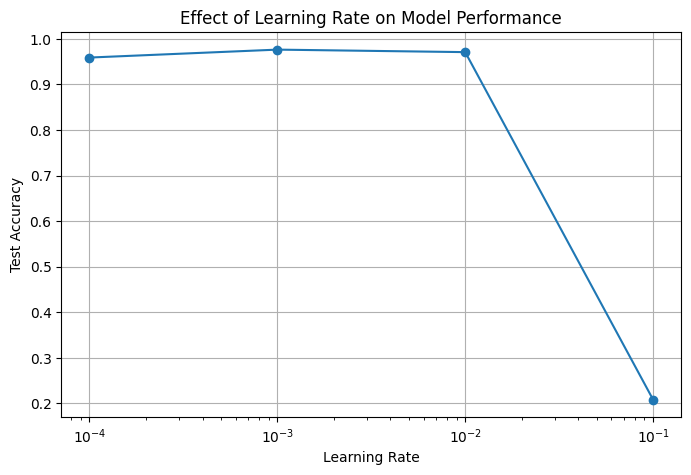

In [11]:
# 8. Plot Learning Rate vs Accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    lr_df["Learning Rate"],
    lr_df["Test Accuracy"],
    marker="o"
)

plt.xscale("log")
plt.xlabel("Learning Rate")
plt.ylabel("Test Accuracy")
plt.title("Effect of Learning Rate on Model Performance")
plt.grid(True)

plt.show()

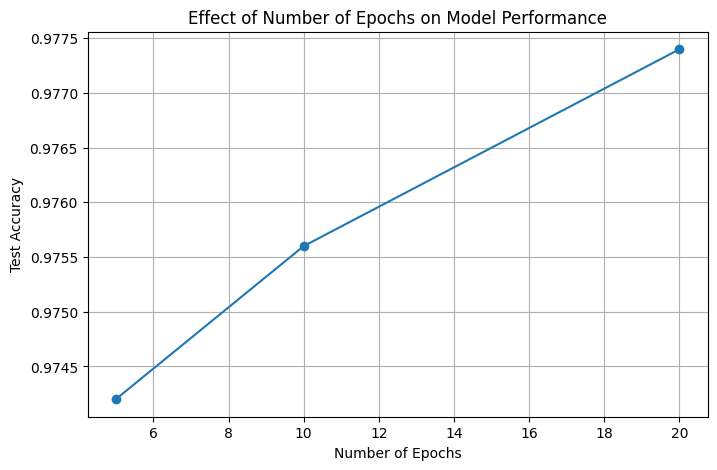

In [12]:
# 9. Plot Epochs vs Accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_df["Epochs"],
    epoch_df["Test Accuracy"],
    marker="o"
)

plt.xlabel("Number of Epochs")
plt.ylabel("Test Accuracy")
plt.title("Effect of Number of Epochs on Model Performance")
plt.grid(True)

plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9036 - loss: 0.3348 - val_accuracy: 0.9533 - val_loss: 0.1596
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9608 - loss: 0.1305 - val_accuracy: 0.9687 - val_loss: 0.1063
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9727 - loss: 0.0919 - val_accuracy: 0.9716 - val_loss: 0.0904
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9793 - loss: 0.0682 - val_accuracy: 0.9745 - val_loss: 0.0837
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9837 - loss: 0.0542 - val_accuracy: 0.9754 - val_loss: 0.0773
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9869 - loss: 0.0421 - val_accuracy: 0.9749 - val_loss: 0.0816
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9895 - loss: 0.0348 - val_accuracy: 0.9762 - val_loss: 0.0786
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9917 - loss: 0.0275 - val_accuracy: 0.

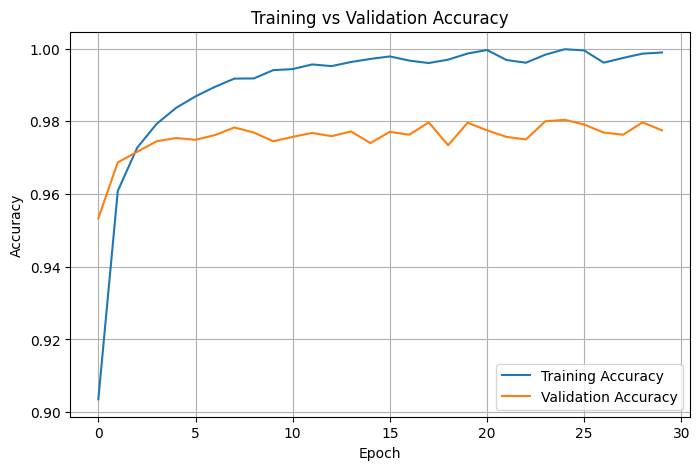

In [13]:
# 10. Training and Validation Accuracy

model = create_model(0.001)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=30,
    batch_size=128,
    verbose=1
)

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

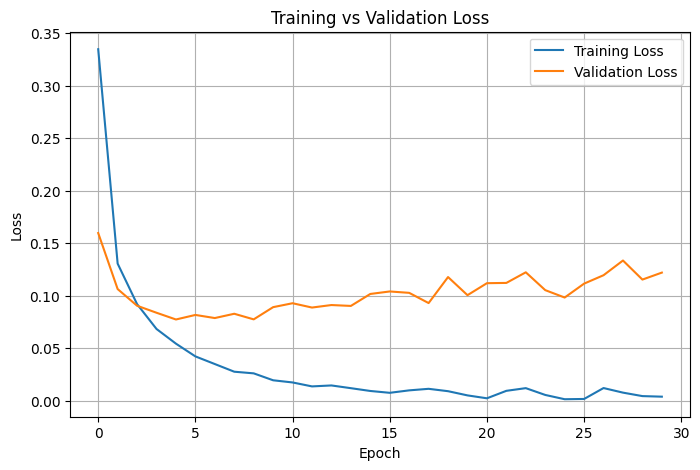

In [14]:
# 11. Training and Validation Loss

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()